<p><b><h2>BERT--TORCH 1.6.0--Transformers <i>for Multi Class Multi Label Classification </i>-- version 1.2</b><br>
<b>The given problem statement falls within the purview of:</b>
<ol>
    <li> <u><b>Multi Class </b>, <b>Multi Label</b> and <b>Multi Lingual</b> -- <b>Text Classification</b></li></u>
        <li> Difference between multi-class classification & multi-label classification is that 
             in multi-class problems the classes are mutually exclusive, whereas for multi-label 
             problems each label represents a different classification task, but the tasks are       somehow related</li>
        <li> For example, multi-class classification makes the assumption that each sample is    assigned to one and only one label: a fruit can be either an apple or a pear but not both at the same time. Whereas, an instance of multi-label classification can be that a text might be about any of religion, politics, finance or education at the same time or none of these
            <li> The current approach tackles the multi class and multi label part; For multi lingual detection <b>NEURAL MACHINE TRANSLATION </b>is recommended as for BERT and other multi-lingual interpretable frameworks, loading of the <b>language specific AutoTokenizer is essential</b>, which requires language detection at transaction level data
            
</ol>

In [1]:
import time
time_start = time.time()

<p><b>Import Libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
%matplotlib inline
import os
import re
import glob
import pickle
import gzip
import random
import pandas as pd
import numpy as np
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
# pd.options.display.float_format='{:.0f}'.format

''' new approach '''
import torch
import torch.nn as nn
from sklearn.metrics import classification_report
import transformers
from transformers import AutoModel, BertTokenizerFast
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
'''optimizer from hugging face transformers'''
from transformers import AdamW
from sklearn.utils.class_weight import compute_class_weight

In [3]:
''' Changing working directory '''
os.chdir(r'/home/tukai/Desktop/Vodafone Work/DL_Data/')

<p><b><h2>Data Load</b><ol><li>Reading data in .gzip <li>Converting to CSV

In [4]:
# pckl_obj.shape

In [5]:
# os.chdir(r'/home/tukai/Desktop/Vodafone Work/DL_Data/')
# file_training = r'For_training.pgz'

# with gzip.GzipFile(file_training, 'rb') as f:
#     pckl_obj = pickle.load(f)

# ''' Writing csv to disk '''
# pckl_obj.to_csv(r'For_training.csv', index=False)

In [6]:
''' Reading '''
data = pd.read_csv(r'For_training.csv', dtype=str, index_col=False).reset_index(drop=True)
''' Trimming Material # '''
data['Material #_new'] = data['Material #'].str.split('.').str[0]
data.drop(['Material #'], axis = 1, inplace=True)
data.rename(columns = {'Material #_new' :'Material #'}, inplace=True)

''' removing Material codes which are non numeric '''
data = data[~data['Material #'].isin(['0x2a'])]

''' Defining dtypes for cols '''
types_dict = {'Short_Text': str, 'Material #': int}
col_names = pd.read_csv('For_training.csv', nrows=0).columns
types_dict.update({col: str for col in col_names if col not in types_dict})
for col, col_type in types_dict.items():
    data[col] = data[col].astype(col_type)

# data = pckl_obj.reset_index(drop=True)

''' Removing duplicate rows '''
data.drop_duplicates(inplace=False)
dataset_mod = data.copy().reset_index(drop=True)
# ''' Text Cleaning --- Special Chars removal --- '''
# dataset_mod['Short_Text'] = dataset_mod['Short_Text'].apply(lambda x: re.sub(r'[\W\_]', ' ', x))
# dataset_mod = dataset_mod.applymap(lambda x : re.sub('\W+',' ', str(x).lower().strip()))

print(f'Shape of the training data after reading : {dataset_mod.shape}')
dataset_mod.head()

Shape of the training data after reading : (986211, 2)


,Short_Text,Material #
0,0 200 km arasi,301023404
1,0 200 km tower,304284303
2,0 200 km tower,304287112
3,0 20m monopol kule demontaji,304284163
4,0 20m monopol kule demontaji,304289940


<b><p><h2>Data Pre-Processing and EDA

In [7]:
dataset_mod.dtypes

Short_Text    object
Material #     int64
dtype: object

In [8]:
''' Text PreProcessing '''

REPLACE_BY_SPACE_RE = re.compile('[/(){}\[\]\|@,;]')
BAD_SYMBOLS_RE = re.compile('[^0-9a-z #+_]')
STOPWORDS = set(stopwords.words('english'))

def clean_text(text):
    """
        text: a string
        
        return: modified initial string
    """
    text = text.lower() # lowercase text
    text = REPLACE_BY_SPACE_RE.sub(' ', text) # replace REPLACE_BY_SPACE_RE symbols by space in text. substitute the matched string in REPLACE_BY_SPACE_RE with space.
    text = BAD_SYMBOLS_RE.sub(' ', text) # remove symbols which are in BAD_SYMBOLS_RE from text. substitute the matched string in BAD_SYMBOLS_RE with nothing. 
    text = text.replace('_', ' ')
    text = text.replace('\d+', '')
    text = re.sub(r'\W+', ' ', text)
    text = re.sub(r'[\W\_]', ' ', text)
    text = ' '.join(word for word in text.split() if word not in STOPWORDS) # remove stopwords from text
    return text
dataset_mod['Short_Text'] = dataset_mod['Short_Text'].apply(clean_text)
# dataset_mod['Short_Text'] = dataset_mod['Short_Text'].str.replace('\d+', '')
print(f'Shape of the training data after applying clean text : {dataset_mod.shape}')
dataset_mod.head()

Shape of the training data after applying clean text : (986211, 2)


,Short_Text,Material #
0,0 200 km arasi,301023404
1,0 200 km tower,304284303
2,0 200 km tower,304287112
3,0 20m monopol kule demontaji,304284163
4,0 20m monopol kule demontaji,304289940


<p><b>Removing whitespaces, empty cells in <i><u>dataset_mod</i></u> where isnull() doesn't recognize <dl><do> Trimming Material # after delimeter

In [9]:
''' Whitespaces '''
dataset_mod['Short_Text'].replace('  ', np.nan, inplace=True)
dataset_mod = dataset_mod.dropna(subset=['Short_Text'])
''' Empty cells '''
dataset_mod['Short_Text'].astype(bool)                                                                                                                      
dataset_mod[dataset_mod['Short_Text'].astype(bool)]
print(f'Shape of the training data after treatment: {dataset_mod.shape}')
dataset_mod.head()

Shape of the training data after treatment: (986211, 2)


,Short_Text,Material #
0,0 200 km arasi,301023404
1,0 200 km tower,304284303
2,0 200 km tower,304287112
3,0 20m monopol kule demontaji,304284163
4,0 20m monopol kule demontaji,304289940


<b><h4>Checking sample instances per class -- before handling

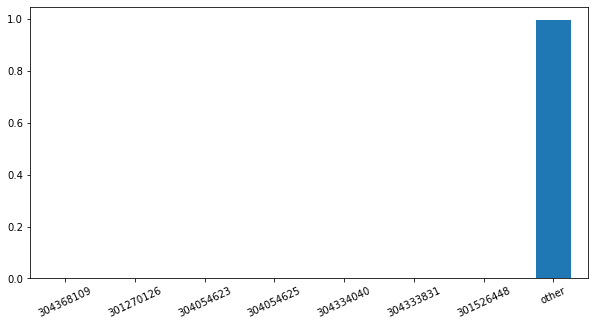

In [10]:
prob = dataset_mod['Material #'].value_counts(normalize=True)
threshold = 0.0002
mask = prob > threshold
tail_prob = prob.loc[~mask].sum()
prob = prob.loc[mask]
prob['other'] = tail_prob
prob.plot(kind='bar',figsize=(10,5))
plt.xticks(rotation=25)
plt.show()

<p><b>Taking top 15 classes as per count of occurrance

In [11]:
dataset_mod['Material #'].groupby(dataset_mod['Short_Text']).value_counts()

Short_Text                               Material #
                                         301191857     1
                                         301202512     1
                                         301202513     1
                                         301203081     1
                                         301203082     1
                                                      ..
zyxel vmg3006                            302061342     1
zyxel zywall 2wg firewall                301193554     1
zyxell p 2602hwl adsl2 voip 4p kablosuz  301193590     1
zyxell1000 base lx sfp                   301193234     1
                                         301193405     1
Name: Material #, Length: 935736, dtype: int64

In [12]:
output_layers = 10
class_largest = dataset_mod['Material #'].value_counts().nlargest(output_layers).keys().tolist()
class_largest

[304368109,
 301270126,
 304054623,
 304054625,
 304334040,
 304333831,
 301526448,
 301270123,
 301608671,
 304333933]

In [13]:
''' Creating sub training data containing the selected 10 Mat Codes'''
data_temp = dataset_mod.loc[dataset_mod['Material #'].isin(class_largest)]
print(f'Shape of the training data after selecting top 15 classes : {data_temp.shape}')
data_temp.head()

Shape of the training data after selecting top 15 classes : (3171, 2)


,Short_Text,Material #
7724,10 001 planung erstellen und dokumentati,301608671
7725,10001 planung und dokumentation,301608671
7726,200000 abrechnung materialkosten,301608671
7727,20002 tiefbau offen gehweg bef 60,301608671
7728,20005 tiefbau offen fahrb asphalt 80,301608671


<p><b>Getting Material Codes for single instances</p></b><dl><l0>Clearly for Material Codes '301304095', '301304106' and '301304104' matching to same Short Text makes it a multi lable problem

In [14]:
dataset_mod[dataset_mod['Material #'].map(dataset_mod['Material #'].value_counts() == 1)]

,Short_Text,Material #
14,1 2 coaxial cable,302055759
288,10gbase lr sfp module,302059800
297,10gbase sr sfp module,302059801
400,158ezdf 7 16 din female ezfit,302056008
551,25mm dc cable blue,302055810
...,...,...
986206,,301578665
986207,co2 2 en 3,301576353
986208,,301580684
986209,,301581223


<p><b>Getting indexes of single instances of Short Text</b><dl>Removing these single instances of Short Texts (i.e. Classes having single sample instance) from universe data

In [15]:
# df_index_rem = dataset_mod[dataset_mod['Short_Text'].map(dataset_mod['Short_Text'].value_counts() == 1)]
# data_temp = dataset_mod[~dataset_mod.index.isin(df_index_rem.index)]

''' Resetting index of Final Data '''
data_final = data_temp.copy().reset_index(drop=True)
print(f'Shape of the final data for train test split : {data_final.shape}')
data_final.head()

Shape of the final data for train test split : (3171, 2)


,Short_Text,Material #
0,10 001 planung erstellen und dokumentati,301608671
1,10001 planung und dokumentation,301608671
2,200000 abrechnung materialkosten,301608671
3,20002 tiefbau offen gehweg bef 60,301608671
4,20005 tiefbau offen fahrb asphalt 80,301608671


In [16]:
data_final.shape

(3171, 2)

In [17]:
data_final['Material #'].unique()

array([301608671, 304054623, 304368109, 304054625, 301270123, 301270126,
       301526448, 304333831, 304334040, 304333933])

<p><b>Encoding the labels     

In [18]:
possible_labels = data_final['Material #'].unique()

label_dict = {}
for index, possible_label in enumerate(possible_labels):
    label_dict[possible_label] = index
label_dict

{301608671: 0,
 304054623: 1,
 304368109: 2,
 304054625: 3,
 301270123: 4,
 301270126: 5,
 301526448: 6,
 304333831: 7,
 304334040: 8,
 304333933: 9}

In [19]:
''' Adding to DF '''
data_final['label'] = data_final['Material #'].replace(label_dict)
data_final.head()

,Short_Text,Material #,label
0,10 001 planung erstellen und dokumentati,301608671,0
1,10001 planung und dokumentation,301608671,0
2,200000 abrechnung materialkosten,301608671,0
3,20002 tiefbau offen gehweg bef 60,301608671,0
4,20005 tiefbau offen fahrb asphalt 80,301608671,0


<b><p>Train Test Split

In [20]:
train_text, temp_text, train_labels, temp_labels = train_test_split(data_final['Short_Text'], data_final['label'], 
                                                                    random_state = 2018, 
                                                                    test_size = 0.3, 
                                                                    stratify = data_final['label'])

'''using temp_text and temp_labels to create validation and test set'''
val_text, test_text, val_labels, test_labels = train_test_split(temp_text, temp_labels, 
                                                                random_state = 2018, 
                                                                test_size = 0.5, 
                                                                stratify = temp_labels)

<p><b>Import BERT Model and BERT Tokenizer

In [21]:
''' import BERT-base pretrained model '''
bert = AutoModel.from_pretrained('bert-base-uncased')

''' Load the BERT tokenizer '''
tokenizer = BertTokenizerFast.from_pretrained('bert-base-uncased')

In [22]:
''' testing the imported model on sample data '''
text = ["this is a bert model tutorial", "we will fine-tune a bert model"]

''' encode text '''
sent_id = tokenizer.batch_encode_plus(text, padding=True, return_token_type_ids=False)
print(sent_id)

{'input_ids': [[101, 2023, 2003, 1037, 14324, 2944, 14924, 4818, 102, 0], [101, 2057, 2097, 2986, 1011, 8694, 1037, 14324, 2944, 102]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]}


<p><b>Tokenization

<AxesSubplot:>

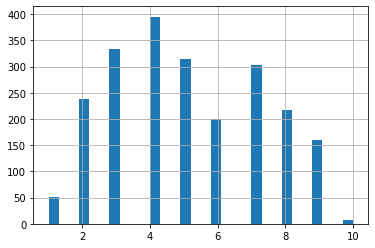

In [23]:
''' Getting length of all the messages in the train set '''
seq_len = [len(i.split()) for i in train_text]
pd.Series(seq_len).hist(bins = 30)

In [24]:
max_seq_len = 25

In [25]:
''' tokenize and encode sequences in the training set '''
tokens_train = tokenizer.batch_encode_plus(
    train_text.tolist(),
    max_length = max_seq_len,
    pad_to_max_length=True,
    truncation=True,
    return_token_type_ids=False
)

''' tokenize and encode sequences in the validation set '''
tokens_val = tokenizer.batch_encode_plus(
    val_text.tolist(),
    max_length = max_seq_len,
    pad_to_max_length=True,
    truncation=True,
    return_token_type_ids=False
)

''' tokenize and encode sequences in the test set '''
tokens_test = tokenizer.batch_encode_plus(
    test_text.tolist(),
    max_length = max_seq_len,
    pad_to_max_length=True,
    truncation=True,
    return_token_type_ids=False
)

<p><b>Convert Integer Sequences to Tensors

In [26]:
''' for train set '''
train_seq = torch.tensor(tokens_train['input_ids'])
train_mask = torch.tensor(tokens_train['attention_mask'])
train_y = torch.tensor(train_labels.tolist())

''' for validation set '''
val_seq = torch.tensor(tokens_val['input_ids'])
val_mask = torch.tensor(tokens_val['attention_mask'])
val_y = torch.tensor(val_labels.tolist())

''' for test set '''
test_seq = torch.tensor(tokens_test['input_ids'])
test_mask = torch.tensor(tokens_test['attention_mask'])
test_y = torch.tensor(test_labels.tolist())

<p><b>Create DataLoaders

In [27]:
''' define a batch size '''
batch_size = 32

''' wrap tensors '''
train_data = TensorDataset(train_seq, train_mask, train_y)

''' sampler for sampling the data during training '''
train_sampler = RandomSampler(train_data)

''' dataLoader for train set '''
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)

''' wrap tensors '''
val_data = TensorDataset(val_seq, val_mask, val_y)

''' sampler for sampling the data during training '''
val_sampler = SequentialSampler(val_data)

''' dataLoader for validation set '''
val_dataloader = DataLoader(val_data, sampler = val_sampler, batch_size=batch_size)

<p><b>Freeze BERT Parameters

In [28]:
for param in bert.parameters(): param.requires_grad = False

<p><b>Define Model Architecture

In [29]:
class BERT_Arch(nn.Module):

    def __init__(self, bert):
      
      super(BERT_Arch, self).__init__()
      self.bert = bert      
      ''' dropout layer '''
      self.dropout = nn.Dropout(0.1)      
      '''relu activation function'''
      self.relu =  nn.ReLU()
      '''dense layer 1'''
      self.fc1 = nn.Linear(768,512)      
      '''dense layer 2 (Output layer)'''
      self.fc2 = nn.Linear(512,output_layers)
      '''softmax activation function'''
      self.softmax = nn.LogSoftmax(dim=1)

    '''define the forward pass'''
    def forward(self, sent_id, mask):

      '''pass the inputs to the model  '''
      _, cls_hs = self.bert(sent_id, attention_mask = mask)
      
      x = self.fc1(cls_hs)
      x = self.relu(x)
      x = self.dropout(x)

      '''output layer'''
      x = self.fc2(x)
      
      '''apply softmax activation'''
      x = self.softmax(x)

      return x

In [30]:
''' defining device for BERT '''
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [31]:
'''pass the pre-trained BERT to our define architecture'''
model = BERT_Arch(bert)

'''push the model to GPU'''
model = model.to(device)

<p><b>Defining OPTIMISER for Activation Function

In [32]:
'''define the optimizer'''
optimizer = AdamW(model.parameters(), lr = 1e-3)

<p><b>Find Class Weights

In [33]:
'''compute the class weights'''
class_wts = compute_class_weight('balanced', np.unique(train_labels), train_labels)
print("Class Weights:",class_wts)

Class Weights: [2.67349398 0.70444444 0.55199005 0.91316872 1.69389313 0.68067485
 1.27528736 0.96899563 0.93235294 2.84487179]


In [34]:
'''convert class weights to tensor'''
weights= torch.tensor(class_wts,dtype=torch.float)
weights = weights.to(device)

'''loss function'''
cross_entropy  = nn.NLLLoss(weight=weights) 

'''number of training epochs'''
epochs = 10

In [35]:
weights

tensor([2.6735, 0.7044, 0.5520, 0.9132, 1.6939, 0.6807, 1.2753, 0.9690, 0.9324,
        2.8449])

<p><b>Fine-Tune BERT

In [36]:
'''function to train the model'''
def train():
    model.train()
    total_loss, total_accuracy = 0, 0
    
    '''empty list to save model predictions'''
    total_preds = []
    
    '''iterate over batches'''
    for step,batch in enumerate(train_dataloader):
        '''progress update after every 50 batches.'''
        if step % 50 == 0 and not step == 0:
            print('  Batch {:>5,}  of  {:>5,}.'.format(step, len(train_dataloader)))
        '''push the batch to gpu'''
        batch = [r.to(device) for r in batch]
        sent_id, mask, labels = batch
        '''clear previously calculated gradients '''
        model.zero_grad()
        '''get model predictions for the current batch'''
        preds = model(sent_id, mask)
        '''compute the loss between actual and predicted values'''
        loss = cross_entropy(preds, labels)
        '''add on to the total loss'''
        total_loss = total_loss + loss.item()
        '''backward pass to calculate the gradients'''
        loss.backward()
        '''clip the the gradients to 1.0. It helps in preventing the exploding gradient problem'''
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        '''update parameters'''
        optimizer.step()
        '''model predictions are stored on GPU. So, push it to CPU'''
        preds=preds.detach().cpu().numpy()
        '''append the model predictions'''
        total_preds.append(preds)
    '''compute the training loss of the epoch'''
    avg_loss = total_loss / len(train_dataloader)
    '''predictions are in the form of (no. of batches, size of batch, no. of classes)'''
    '''reshape the predictions in form of (number of samples, no. of classes)'''
    total_preds  = np.concatenate(total_preds, axis=0)
    '''returns the loss and predictions'''
    return avg_loss, total_preds

In [37]:
''' function for evaluating the model '''
def evaluate():
    print("\nEvaluating...")
    '''deactivate dropout layers'''
    model.eval()
    total_loss, total_accuracy = 0, 0
    '''empty list to save the model predictions'''
    total_preds = []
    '''iterate over batches'''
    for step,batch in enumerate(val_dataloader):
        '''Progress update every 50 batches.'''
        if step % 50 == 0 and not step == 0:
            '''Calculate elapsed time in minutes.'''
            elapsed = format_time(time.time() - t0)
            '''Report progress.'''
            print('  Batch {:>5,}  of  {:>5,}.'.format(step, len(val_dataloader)))
        '''push the batch to gpu'''
        batch = [t.to(device) for t in batch]
        sent_id, mask, labels = batch
        '''deactivate autograd'''
        with torch.no_grad():
            '''model predictions'''
            preds = model(sent_id, mask)
            '''compute the validation loss between actual and predicted values'''
            loss = cross_entropy(preds,labels)
            total_loss = total_loss + loss.item()
            preds = preds.detach().cpu().numpy()
            total_preds.append(preds)
        '''compute the validation loss of the epoch'''
        avg_loss = total_loss / len(val_dataloader)
        '''reshape the predictions in form of (number of samples, no. of classes)'''
        total_preds  = np.concatenate(total_preds, axis=0)
        return avg_loss, total_preds


<p><b>Start Model Training

In [38]:
''' setting initial lossto inf '''
best_valid_loss = float('inf')

'''empty lists to store training and validation loss of each epoch'''
train_losses=[]
valid_losses=[]

'''for each epoch'''
for epoch in range(epochs):
     
    print('\n Epoch {:} / {:}'.format(epoch + 1, epochs))
    
    '''train model'''
    train_loss, _ = train()
    
    '''evaluate model'''
    valid_loss, _ = evaluate()
    
    '''save the best model'''
    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), 'saved_weights.pt')
    
    '''append training and validation loss'''
    train_losses.append(train_loss)
    valid_losses.append(valid_loss)
    
    print(f'\nTraining Loss: {train_loss:.3f}')
    print(f'Validation Loss: {valid_loss:.3f}')


 Epoch 1 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 2.083
Validation Loss: 0.141

 Epoch 2 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.810
Validation Loss: 0.109

 Epoch 3 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.742
Validation Loss: 0.099

 Epoch 4 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.677
Validation Loss: 0.090

 Epoch 5 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.651
Validation Loss: 0.083

 Epoch 6 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.609
Validation Loss: 0.076

 Epoch 7 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.573
Validation Loss: 0.082

 Epoch 8 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.554
Validation Loss: 0.071

 Epoch 9 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.551
Validation Loss: 0.075

 Epoch 10 / 10
  Batch    50  of     70.

Evaluating...

Training Loss: 1.542
Validation L

<p><b>Load Saved Model

In [39]:
'''load weights of best model'''
path = 'saved_weights.pt'
model.load_state_dict(torch.load(path))

<All keys matched successfully>

<p><b>Get Predictions for Test Data

In [40]:
'''get predictions for test data'''
with torch.no_grad():
    preds = model(test_seq.to(device), test_mask.to(device))
    preds = preds.detach().cpu().numpy()

In [41]:
'''model's performance'''
preds = np.argmax(preds, axis = 1)
print(classification_report(test_y, preds))

              precision    recall  f1-score   support

           0       0.67      1.00      0.80        18
           1       0.27      0.38      0.31        68
           2       0.00      0.00      0.00        86
           3       0.13      0.13      0.13        52
           4       0.10      0.57      0.16        28
           5       0.00      0.00      0.00        70
           6       0.24      0.11      0.15        37
           7       0.00      0.00      0.00        49
           8       0.00      0.00      0.00        51
           9       0.15      1.00      0.26        17

    accuracy                           0.18       476
   macro avg       0.15      0.32      0.18       476
weighted avg       0.11      0.18      0.12       476



In [42]:
'''confusion matrix'''
pd.crosstab(test_y, preds)

col_0,0,1,3,4,6,9
row_0,,,,,,
0,18,0,0,0,0,0
1,1,26,8,29,4,0
2,4,17,11,49,5,0
3,1,16,7,25,3,0
4,0,7,5,16,0,0
5,1,16,10,42,1,0
6,0,16,12,5,4,0
7,2,0,0,0,0,47
8,0,0,0,0,0,51


In [43]:
end_time = time.time()
print(f'Total time taken for the program to execute : {(end_time - time_start)/60} min')

Total time taken for the program to execute : 20.04817400376002 min
